# Objective 2 — Sales data preprocessing

**Input:** `docs/data/etech_sales_2022_2026.csv`, eTech's sales history from January 2022 to August 2026.
**Output:** cleaned tables in `ml/data/processed/`, ready for sales prediction.

> **The sales are synthetic.** They were generated for this project and approved for FYP use by the
> shop owner under a signed agreement. The 389 catalogue products and their prices are real; the sales
> are not a record of real trading (see `docs/data/README.md`).
>
> **Confidentiality.** Under that agreement nothing produced here may show customer personal data,
> supplier details, cost prices or profit margins. The dataset holds none of them, and step 1
> checks that before anything else runs.

Steps:

1. Load the data and check it holds no confidential fields
2. Check data quality
3. **Remove services** (product sales only, for now)
4. Fix column types and add flags
5. Look at outliers
6. Build the **weekly** sales series (and the monthly one, for the report)
7. Engineer forecasting features
8. Split by time into train and test
9. Save the outputs

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Run from ml/ or from the repo root
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
RAW = ROOT / "docs" / "data" / "etech_sales_2022_2026.csv"
RAW_MONTHLY = ROOT / "docs" / "data" / "etech_sales_monthly.csv"
OUT = ROOT / "ml" / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

# Chart style: validated categorical palette (fixed order), recessive axes
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

log = []  # (step, rows, bills, revenue) - the audit trail for the report
def record(step, frame):
    log.append({"step": step, "rows": len(frame), "bills": frame["saleId"].nunique(),
                "revenue_RM": round(frame["lineTotal"].sum(), 2)})

## 1. Load the data and check for confidential fields

In [2]:
raw = pd.read_csv(RAW, encoding="utf-8-sig")  # the file starts with a byte-order mark
print(raw.shape)
raw.head()

(49720, 15)


,saleId,lineNo,date,year,month,orderType,paymentMethod,sku,itemType,itemName,category,brand,quantity,unitPrice,lineTotal
0,CINV-0001-0122,1,2022-01-01,2022,1,RETAIL,CASH,P-4208,PRODUCT,Cooler Master MF120 Lite 120mm (Black),Case Fans,Cooler Master,1,54.17,54.17
1,CINV-0001-0122,2,2022-01-01,2022,1,RETAIL,CASH,P-3029,PRODUCT,Kingston Fury Beast 32GB DDR4-3200MHz,RAM,Kingston,1,922.13,922.13
2,CINV-0002-0122,1,2022-01-01,2022,1,RETAIL,CASH,P-4314,PRODUCT,Deepcool RGB 200 Pro,ARGB Lighting,Deepcool,1,90.07,90.07
3,CINV-0002-0122,2,2022-01-01,2022,1,RETAIL,CASH,SVC-006,SERVICE,Laptop Screen Replacement (labour),Services,Services,1,193.84,193.84
4,CINV-0003-0122,1,2022-01-01,2022,1,RETAIL,CASH,P-3209,PRODUCT,Hiksemi Wave 512GB PCIe Gen 3 NVMe SSD,Storage,Hiksemi,2,220.82,441.64


In [3]:
# The agreement forbids these kinds of field. Fail loudly if any column looks like one.
FORBIDDEN = ["customer", "name_of", "phone", "email", "address", "supplier",
             "cost", "profit", "margin", "wholesale"]
hits = [c for c in raw.columns if any(f in c.lower() for f in FORBIDDEN)]
assert not hits, f"Confidential columns present: {hits}"
print("Columns:", list(raw.columns))
print("No customer, supplier, cost or margin columns - safe to process.")
record("loaded", raw)

Columns: ['saleId', 'lineNo', 'date', 'year', 'month', 'orderType', 'paymentMethod', 'sku', 'itemType', 'itemName', 'category', 'brand', 'quantity', 'unitPrice', 'lineTotal']
No customer, supplier, cost or margin columns - safe to process.


## 2. Check data quality

In [4]:
checks = pd.Series({
    "missing values": int(raw.isna().sum().sum()),
    "duplicate rows": int(raw.duplicated().sum()),
    "duplicate saleId + lineNo": int(raw.duplicated(["saleId", "lineNo"]).sum()),
    "quantity <= 0": int((raw["quantity"] <= 0).sum()),
    "unitPrice <= 0": int((raw["unitPrice"] <= 0).sum()),
    "lineTotal != quantity x unitPrice": int(((raw["quantity"] * raw["unitPrice"] - raw["lineTotal"]).abs() > 0.01).sum()),
})
dates = pd.to_datetime(raw["date"], format="%Y-%m-%d", errors="coerce")
checks["unparseable dates"] = int(dates.isna().sum())
checks["year column disagrees with date"] = int((dates.dt.year != raw["year"]).sum())
checks["month column disagrees with date"] = int((dates.dt.month != raw["month"]).sum())
checks["saleId suffix (MMYY) disagrees with date"] = int((raw["saleId"].str[-4:] != dates.dt.strftime("%m%y")).sum())
per_bill = raw.groupby("saleId")[["date", "orderType", "paymentMethod"]].nunique()
checks["bills spanning more than one date / orderType / payment"] = int((per_bill > 1).any(axis=1).sum())
checks.to_frame("problem rows")

,problem rows
missing values,0
duplicate rows,0
duplicate saleId + lineNo,0
quantity <= 0,0
unitPrice <= 0,0
lineTotal != quantity x unitPrice,0
unparseable dates,0
year column disagrees with date,0
month column disagrees with date,0
saleId suffix (MMYY) disagrees with date,0


In [5]:
print("Date range:", dates.min().date(), "to", dates.max().date())
expected = pd.period_range(dates.min(), dates.max(), freq="M")
present = dates.dt.to_period("M").unique()
print(f"Months: {len(present)} of {len(expected)} expected;",
      "none missing" if len(present) == len(expected) else f"missing {sorted(set(expected) - set(present))}")

Date range: 2022-01-01 to 2026-08-31
Months: 56 of 56 expected; none missing


In [6]:
# Cross-check: the line file must add up to the published monthly summary
monthly_pub = pd.read_csv(RAW_MONTHLY, encoding="utf-8-sig")
rebuilt = raw.groupby(raw["date"].str[:7])["lineTotal"].sum().round(2)
gap = (rebuilt - monthly_pub.set_index("period")["revenue"]).abs().max()
print(f"Largest monthly revenue gap vs etech_sales_monthly.csv: RM {gap:.2f}")
assert gap < 0.01

Largest monthly revenue gap vs etech_sales_monthly.csv: RM 0.00


Every check comes back **zero**, which is expected of generated data. The notebook keeps the
checks anyway: they document that the data was checked rather than assumed clean, and they
would catch any problem if the data were regenerated or replaced with real records.

## 3. Remove services

Services (assembly, repairs, OS installs, warranties) are labour, not stock, and are left out of
sales prediction for now. A service line is marked in three consistent ways, confirmed below:
`itemType == "SERVICE"`, category `Services` and SKU prefix `SVC-`.

A bill can be:
- **service-only** (e.g. a repair visit): it disappears entirely;
- **mixed** (e.g. a rig build with an assembly charge): its product lines stay and the service line goes;
- **product-only**: unchanged.

In [7]:
is_service = raw["itemType"].eq("SERVICE")
assert is_service.equals(raw["category"].eq("Services"))
assert is_service.equals(raw["sku"].str.startswith("SVC-"))

bill_kind = (raw.assign(svc=is_service).groupby("saleId")["svc"]
               .agg(lambda s: "service-only" if s.all() else "mixed" if s.any() else "product-only"))
print(bill_kind.value_counts().to_string(), "\n")

services = raw[is_service]
print(f"Service lines removed: {len(services):,} ({len(services)/len(raw):.1%} of lines)")
print(f"Service revenue removed: RM {services['lineTotal'].sum():,.2f} "
      f"({services['lineTotal'].sum()/raw['lineTotal'].sum():.1%} of revenue)")
services.groupby("itemName")["lineTotal"].agg(lines="count", revenue_RM="sum").sort_values("revenue_RM", ascending=False).round(2)

svc
product-only    8414
mixed           5351
service-only    2882 

Service lines removed: 9,969 (20.1% of lines)
Service revenue removed: RM 1,392,702.26 (7.9% of revenue)


,lines,revenue_RM
itemName,,
Data Recovery (per drive),541,245373.61
Extended Warranty (1 Year),971,243527.60
PC Assembly & Build Service,1609,154873.88
Operating System Installation,1569,114617.13
Data Backup & Transfer,839,104077.78
Laptop Screen Replacement (labour),545,102578.64
On-Site Diagnostic Visit,608,89762.09
Thermal Paste Reapplication,1018,89564.30
Laptop Keyboard Replacement (labour),519,76737.82


In [8]:
sales = raw[~is_service].copy()
assert not sales["itemType"].eq("SERVICE").any()
record("services removed", sales)

# The product total must equal the published productRevenue column month by month
prod_rebuilt = sales.groupby(sales["date"].str[:7])["lineTotal"].sum().round(2)
assert (prod_rebuilt - monthly_pub.set_index("period")["productRevenue"]).abs().max() < 0.01
print(f"{len(sales):,} product lines across {sales['saleId'].nunique():,} bills remain; "
      "they match the published productRevenue for all 56 months.")

39,751 product lines across 13,765 bills remain; they match the published productRevenue for all 56 months.


`lineNo` is left as it was, so a mixed bill may now read 1, 2, 4. That keeps every row traceable
back to the original file; `saleId + lineNo` is still unique.

## 4. Fix column types and add flags

In [9]:
sales["date"] = pd.to_datetime(sales["date"], format="%Y-%m-%d")
sales["period"] = sales["date"].dt.to_period("M")
for col in ["orderType", "paymentMethod", "itemType", "category", "brand"]:
    sales[col] = sales[col].astype("category")
sales = sales.drop(columns="itemType")  # a single value ("PRODUCT") now - carries no information

# Flag the invented stock (kept, but easy to filter out): the cables and peripherals the generator
# added, and the dated machines (SKU "M-"). Genuine catalogue products have SKU "P-".
sales["isCatalogueProduct"] = sales["sku"].str.startswith("P-")
sales["isInventedStock"] = (sales["category"].isin(["Cables", "Peripherals"])
                            | sales["sku"].str.startswith("M-"))
print(sales.dtypes.to_string())
print()
print(sales.groupby("isInventedStock", observed=True)["lineTotal"].agg(lines="count", revenue_RM="sum").round(2))

saleId                           str
lineNo                         int64
date                  datetime64[us]
year                           int64
month                          int64
orderType                   category
paymentMethod               category
sku                              str
itemName                         str
category                    category
brand                       category
quantity                       int64
unitPrice                    float64
lineTotal                    float64
period                     period[M]
isCatalogueProduct              bool
isInventedStock                 bool



                 lines   revenue_RM
isInventedStock                    
False            29903  13915926.89
True              9848   2373170.55


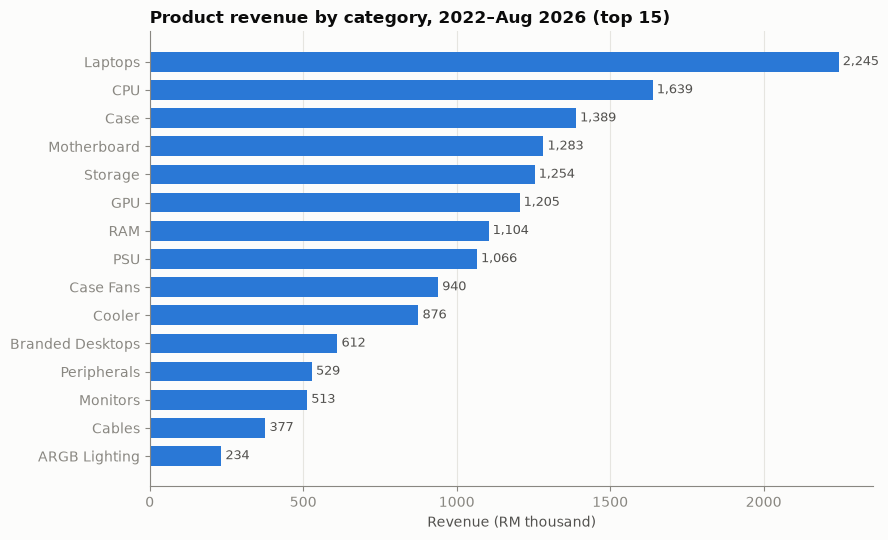

In [10]:
by_cat = sales.groupby("category", observed=True)["lineTotal"].sum().sort_values()
top = by_cat.tail(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index.astype(str), top.values / 1e3, color=BLUE, height=0.7)
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("Product revenue by category, 2022–Aug 2026 (top 15)")
ax.set_xlabel("Revenue (RM thousand)")
for y, v in enumerate(top.values / 1e3):
    ax.text(v, y, f" {v:,.0f}", va="center", color=INK_2, fontsize=9)
plt.tight_layout(); plt.show()

## 5. Look at outliers

The only thing that could be an outlier here is a bill's value. It is checked with the 1.5 × IQR rule
on bill totals, split by order type, because a rig build (a whole PC) is expected to cost many times a
counter sale.

In [11]:
bills = (sales.groupby(["saleId", "orderType"], observed=True)
              .agg(date=("date", "first"), lines=("lineNo", "count"),
                   units=("quantity", "sum"), billTotal=("lineTotal", "sum"))
              .reset_index())

def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

bills["isOutlier"] = bills.groupby("orderType", observed=True)["billTotal"].transform(iqr_flags)
bills.groupby("orderType", observed=True).agg(
    bills=("saleId", "count"), median_RM=("billTotal", "median"),
    max_RM=("billTotal", "max"), outliers=("isOutlier", "sum")).round(2)

,bills,median_RM,max_RM,outliers
orderType,,,,
PREBUILT,447,2575.35,9584.29,28
RETAIL,12197,379.47,17675.95,1282
RIG_BUILD,1121,4245.32,20330.44,20


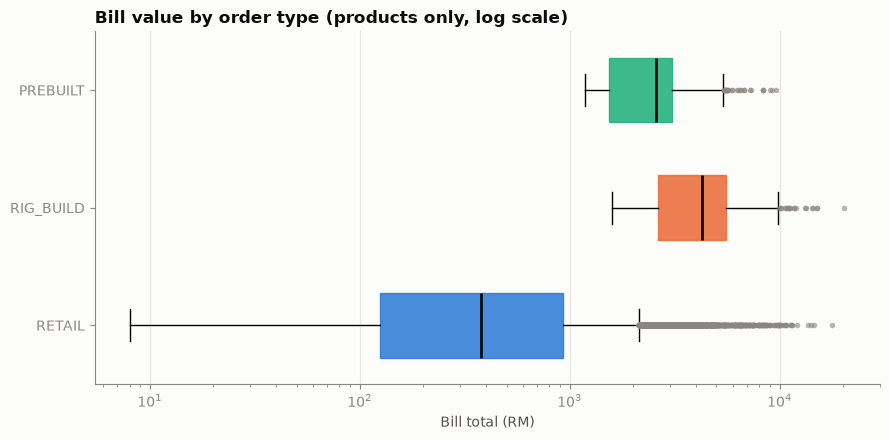

In [12]:
order = ["RETAIL", "RIG_BUILD", "PREBUILT"]
colors = [BLUE, ORANGE, AQUA]
fig, ax = plt.subplots(figsize=(9, 4.5))
parts = ax.boxplot([bills.loc[bills["orderType"] == o, "billTotal"] for o in order],
                   tick_labels=order, orientation="horizontal", patch_artist=True, widths=0.55,
                   medianprops={"color": INK, "linewidth": 2},
                   flierprops={"marker": "o", "markersize": 4, "markerfacecolor": MUTED,
                               "markeredgecolor": "none", "alpha": 0.6})
for patch, c in zip(parts["boxes"], colors):
    patch.set(facecolor=c, edgecolor=c, alpha=0.85)
ax.set_xscale("log")
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.set_title("Bill value by order type (products only, log scale)")
ax.set_xlabel("Bill total (RM)")
plt.tight_layout(); plt.show()

Retail flags far more bills (roughly one in ten) than the other two types. That is a property of the rule, not of
the data: counter sales run from an RM 8 cable to a whole laptop, so the spread is very right-skewed and a
1.5 × IQR fence catches the entire expensive tail.

**Decision: keep every outlier.** The flagged bills are real kinds of sale, not errors: a bulk office
purchase, or a build with a high-end graphics card. Removing them would teach the model that big sales
never happen. The `isOutlier` flag is saved with the bill table so a later model can test with and without them.

## 6. Build the weekly sales series

The model is trained on **weekly** sales, not monthly. 56 months leaves only 48 rows to train on, and 36 once
the 12-month lag is taken: enough for a simple trend-and-season model, too few for a machine-learning model to
learn anything but those rows. The same sales summed by week give **243 weeks**, 208 to train on and 35 to test.

- A week runs **Monday to Sunday** and belongs to the year its Thursday falls in (ISO 8601), so
  29 Dec 2025 – 4 Jan 2026 is week 1 of 2026.
- The file starts on Saturday 1 January 2022 and ends on Monday 31 August 2026. Those two **partial weeks**
  (two days and one day) are left out of the weekly series, because a one-day "week" would look like a collapse
  in sales. The sale lines themselves are kept.
- The **monthly series is still built**. The report's charts are monthly, the shop's sales targets are
  monthly, and a weekly forecast can be summed back into months.

In [13]:
monthly = (sales.groupby("period")
                .agg(bills=("saleId", "nunique"), lines=("lineNo", "count"),
                     units=("quantity", "sum"), revenue=("lineTotal", "sum"))
                .reindex(pd.period_range("2022-01", "2026-08", freq="M"), fill_value=0))
monthly.index.name = "period"
monthly["revenue"] = monthly["revenue"].round(2)
monthly["avgBillValue"] = (monthly["revenue"] / monthly["bills"]).round(2)
assert (monthly["bills"] > 0).all(), "a month with no sales - check before forecasting"
print(len(monthly), "months")
monthly.head(12)

56 months


,bills,lines,units,revenue,avgBillValue
period,,,,,
2022-01,463,1307,2095,507990.80,1097.17
2022-02,342,1042,1657,389252.09,1138.16
2022-03,349,975,1618,345042.47,988.66
2022-04,417,1249,1955,487051.05,1167.99
2022-05,387,1119,1816,451952.82,1167.84
2022-06,335,955,1495,384523.86,1147.83
2022-07,343,951,1499,340392.70,992.40
2022-08,370,1072,1766,407028.77,1100.08
2022-09,386,1044,1734,362487.70,939.09


In [14]:
FIRST_WEEK, LAST_WEEK = pd.Timestamp("2022-01-03"), pd.Timestamp("2026-08-24")  # Mondays of the first and last full week
assert FIRST_WEEK.weekday() == 0 and LAST_WEEK.weekday() == 0
sales["weekStart"] = sales["date"] - pd.to_timedelta(sales["date"].dt.weekday, unit="D")

edge = sales[~sales["weekStart"].between(FIRST_WEEK, LAST_WEEK)]
print(f"Partial weeks left out: {len(edge)} lines, {edge['saleId'].nunique()} bills, "
      f"RM {edge['lineTotal'].sum():,.2f}, dated {', '.join(sorted(edge['date'].dt.strftime('%d %b %Y').unique()))}")

weekly = (sales[sales["weekStart"].between(FIRST_WEEK, LAST_WEEK)]
               .groupby("weekStart")
               .agg(bills=("saleId", "nunique"), lines=("lineNo", "count"),
                    units=("quantity", "sum"), revenue=("lineTotal", "sum"))
               .reindex(pd.date_range(FIRST_WEEK, LAST_WEEK, freq="W-MON"), fill_value=0))
weekly.index.name = "weekStart"
weekly["revenue"] = weekly["revenue"].round(2)
weekly["avgBillValue"] = (weekly["revenue"] / weekly["bills"]).round(2)
iso = weekly.index.isocalendar()
weekly.insert(0, "isoYear", iso["year"].astype(int).to_numpy())
weekly.insert(1, "isoWeek", iso["week"].astype(int).to_numpy())
assert (weekly["bills"] > 0).all(), "a week with no sales - check before forecasting"
print(len(weekly), "weeks:", weekly.groupby("isoYear").size().to_dict())
weekly.head()

Partial weeks left out: 142 lines, 44 bills, RM 73,881.25, dated 01 Jan 2022, 02 Jan 2022, 31 Aug 2026
243 weeks: {2022: 52, 2023: 52, 2024: 52, 2025: 52, 2026: 35}


,isoYear,isoWeek,bills,lines,units,revenue,avgBillValue
weekStart,,,,,,,
2022-01-03,2022,1,105,333,526,144476.24,1375.96
2022-01-10,2022,2,108,290,449,96819.86,896.48
2022-01-17,2022,3,105,303,484,128964.95,1228.24
2022-01-24,2022,4,95,231,384,76976.96,810.28
2022-01-31,2022,5,88,239,378,83812.77,952.42


**What a week can and cannot show.** The generator picks each sale's day at random within its month, so a
week has no weekday, payday or one-day-sale pattern of its own to find. A weekly series carries the same trend
and monthly seasonality as the monthly one, **with more noise**, because each week rests on far fewer bills.
That noise is the price of four times the rows. It is also why step 7 encodes the season by month, not by week of
the year. The table below measures it.

In [15]:
m26, w26 = monthly[monthly.index.year == 2026], weekly[weekly["isoYear"] == 2026]
pd.DataFrame({
    "rows": [len(monthly), len(weekly)],
    "mean revenue (RM)": [monthly["revenue"].mean(), weekly["revenue"].mean()],
    "coefficient of variation": [monthly["revenue"].std() / monthly["revenue"].mean(),
                                 weekly["revenue"].std() / weekly["revenue"].mean()],
    "2026: fewest bills": [m26["bills"].min(), w26["bills"].min()],
    "2026: median bills": [m26["bills"].median(), w26["bills"].median()],
    "2026: lowest revenue (RM)": [m26["revenue"].min(), w26["revenue"].min()],
}, index=["monthly", "weekly"]).round(2)

,rows,mean revenue (RM),coefficient of variation,2026: fewest bills,2026: median bills,2026: lowest revenue (RM)
monthly,56,290876.74,0.34,77,93.0,109355.46
weekly,243,66729.28,0.38,12,22.0,12118.55


In [16]:
# The same series per category, long format - for category-level forecasts later
monthly_category = (sales.groupby(["period", "category"], observed=True)
                         .agg(lines=("lineNo", "count"), units=("quantity", "sum"), revenue=("lineTotal", "sum"))
                         .round(2).reset_index())
monthly_category.head()

,period,category,lines,units,revenue
0,2022-01,AIO Desktops,3,4,14493.18
1,2022-01,ARGB Lighting,56,122,12308.58
2,2022-01,Branded Desktops,8,8,19627.11
3,2022-01,CPU,55,56,40447.16
4,2022-01,Cable Kits,16,32,4815.87


In [17]:
yearly = monthly.groupby(monthly.index.year).agg(months=("bills", "size"), bills=("bills", "sum"), revenue=("revenue", "sum"))
yearly["revenuePerMonth"] = (yearly["revenue"] / yearly["months"]).round(2)
yearly["changeVsPrevYear"] = yearly["revenuePerMonth"].pct_change().map(lambda x: f"{x:+.1%}" if pd.notna(x) else "")
yearly

,months,bills,revenue,revenuePerMonth,changeVsPrevYear
period,,,,,
2022,12,4540,4959882.99,413323.58,
2023,12,3463,4025915.21,335492.93,-18.8%
2024,12,2728,3174015.78,264501.32,-21.2%
2025,12,2258,2835659.49,236304.96,-10.7%
2026,8,776,1293623.97,161703.00,-31.6%


**Say this before the viva panel does.** The sales fall every year because the generator was told to.
The **size and timing** of the fall come from the shop owner: about 100 receipts a week in 2022, about 50
just before the RAM crisis, about 30 through 2026, every receipt counted. The generator reproduces that with
about −20 % of customers a year plus a **component price shock** from October 2025 to June 2026, modelled
on the reported AI-driven memory shortage (RAM about 3×, SSDs 2.5×, GPUs 1.5×, CPUs and motherboards up
15–20 %, 37 % of customers lost by the peak). **Which products, prices and baskets** fill each receipt are
generated. A model that forecasts this decline correctly proves the **pipeline works** and follows the
owner's account of the business; it has not learned from eTech's real receipts.

## 7. Engineer forecasting features

In [18]:
features = weekly[["isoYear", "isoWeek", "revenue", "bills", "units"]].copy()
features["t"] = np.arange(len(features))                    # trend index: 0 = week of 3 Jan 2022
# Season by the month the week mostly falls in (its Thursday's month). The generator's seasonality is monthly,
# and 11 month dummies are far easier to fit on 208 weeks than 51 week-of-year dummies.
thursday = features.index + pd.Timedelta(days=3)
features["month"] = thursday.month
features["quarter"] = thursday.quarter
features = features.join(pd.get_dummies(features["month"], prefix="m", drop_first=True, dtype=int))
# Lags and rolling means use only past weeks (shift first) - no look-ahead leakage.
# 52 weeks back is the same ISO week last year for every year in the file.
features["revenue_lag1"] = features["revenue"].shift(1)
features["revenue_lag52"] = features["revenue"].shift(52)
features["revenue_roll4"] = features["revenue"].shift(1).rolling(4).mean().round(2)
print("Weeks with a missing lag (the first 52 have no lag-52):", int(features["revenue_lag52"].isna().sum()))
features.iloc[50:55]

Weeks with a missing lag (the first 52 have no lag-52): 52


,isoYear,isoWeek,revenue,bills,units,t,month,quarter,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12,revenue_lag1,revenue_lag52,revenue_roll4
weekStart,,,,,,,,,,,,,,,,,,,,,,
2022-12-19,2022,51,123494.51,102,508,50,12,4,0,0,0,0,0,0,0,0,0,0,1,69407.23,NaN,88996.26
2022-12-26,2022,52,106115.45,92,478,51,12,4,0,0,0,0,0,0,0,0,0,0,1,123494.51,NaN,93664.61
2023-01-02,2023,1,98882.77,78,442,52,1,1,0,0,0,0,0,0,0,0,0,0,0,106115.45,144476.24,98880.50
2023-01-09,2023,2,91728.72,76,362,53,1,1,0,0,0,0,0,0,0,0,0,0,0,98882.77,96819.86,99474.99
2023-01-16,2023,3,83633.62,84,380,54,1,1,0,0,0,0,0,0,0,0,0,0,0,91728.72,128964.95,105055.36


In [19]:
# The monthly table, kept for comparison and for the report
features_m = monthly[["revenue", "bills", "units"]].copy()
features_m["t"] = np.arange(len(features_m))                # trend index: 0 = Jan 2022
features_m["monthOfYear"] = features_m.index.month
features_m["quarter"] = features_m.index.quarter
features_m = features_m.join(pd.get_dummies(features_m["monthOfYear"], prefix="m", drop_first=True, dtype=int))
features_m["revenue_lag1"] = features_m["revenue"].shift(1)
features_m["revenue_lag12"] = features_m["revenue"].shift(12)
features_m["revenue_roll3"] = features_m["revenue"].shift(1).rolling(3).mean().round(2)
features_m.iloc[10:15]

,revenue,bills,units,t,monthOfYear,quarter,m_2,m_3,m_4,m_5,m_6,m_7,m_8,m_9,m_10,m_11,m_12,revenue_lag1,revenue_lag12,revenue_roll3
period,,,,,,,,,,,,,,,,,,,,
2022-11,402081.82,371,1691,10,11,4,0,0,0,0,0,0,0,0,0,1,0,458031.10,NaN,409182.52
2022-12,424047.81,413,1982,11,12,4,0,0,0,0,0,0,0,0,0,0,1,402081.82,NaN,407533.54
2023-01,387658.54,343,1607,12,1,1,0,0,0,0,0,0,0,0,0,0,0,424047.81,507990.80,428053.58
2023-02,280925.50,244,1171,13,2,1,1,0,0,0,0,0,0,0,0,0,0,387658.54,389252.09,404596.06
2023-03,271579.82,279,1195,14,3,1,0,1,0,0,0,0,0,0,0,0,0,280925.50,345042.47,364210.62


The first 52 weeks have no `revenue_lag52` (and the first 12 months no `revenue_lag12`). They are **kept** in the
files, not dropped: a trend-plus-season model does not need lags, and a lag model can drop them itself.
Dropping them here would throw away a year of data for every model.

## 8. Split by time into train and test

Time series are split **by date, never randomly**: a random split would let the model train on the future.

- **Train:** ISO weeks 2022-W01 to 2025-W52 (3 Jan 2022 – 28 Dec 2025), 208 weeks, four full years, so every
  month of the year appears four times
- **Test:** ISO weeks 2026-W01 to 2026-W35 (29 Dec 2025 – 30 Aug 2026), the most recent 35 weeks

Week 1 of 2026 holds three days of December 2025, by the ISO rule. The monthly split stays at January 2026:
48 months to train on, 8 to test.

In [20]:
train = features[features["isoYear"] < 2026]
test = features[features["isoYear"] >= 2026]
print(f"weekly  train: {train.index.min().date()} - {train.index.max().date()}  ({len(train)} weeks)")
print(f"weekly  test:  {test.index.min().date()} - {test.index.max().date()}  ({len(test)} weeks)")
assert len(train) + len(test) == len(features) and train.index.max() < test.index.min()

SPLIT_M = pd.Period("2026-01", freq="M")
train_m = features_m[features_m.index < SPLIT_M]
test_m = features_m[features_m.index >= SPLIT_M]
print(f"monthly train: {train_m.index.min()} - {train_m.index.max()}  ({len(train_m)} months)")
print(f"monthly test:  {test_m.index.min()} - {test_m.index.max()}  ({len(test_m)} months)")
assert len(train_m) + len(test_m) == len(features_m) and train_m.index.max() < test_m.index.min()

weekly  train: 2022-01-03 - 2025-12-22  (208 weeks)
weekly  test:  2025-12-29 - 2026-08-24  (35 weeks)
monthly train: 2022-01 - 2025-12  (48 months)
monthly test:  2026-01 - 2026-08  (8 months)


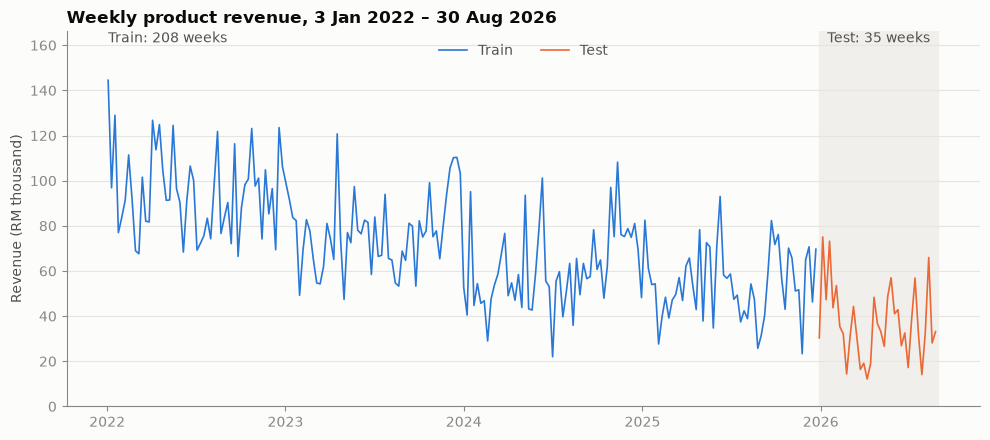

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(test.index.min(), test.index.max() + pd.Timedelta(days=6), color="#f0efec", zorder=0)
ax.plot(train.index, train["revenue"] / 1e3, color=BLUE, linewidth=1.2, label="Train")
ax.plot(test.index, test["revenue"] / 1e3, color=ORANGE, linewidth=1.2, label="Test")
ax.set_ylim(0, features["revenue"].max() / 1e3 * 1.15)
top = ax.get_ylim()[1]
ax.text(train.index.min(), top, f"Train: {len(train)} weeks", color=INK_2, va="top")
ax.text(test.index.min(), top, f"  Test: {len(test)} weeks", color=INK_2, va="top")
ax.set_title("Weekly product revenue, 3 Jan 2022 – 30 Aug 2026")
ax.set_ylabel("Revenue (RM thousand)")
ax.legend(frameon=False, loc="upper center", ncols=2, labelcolor=INK_2)
plt.tight_layout(); plt.show()

## 9. Save the outputs

Every table is written as a CSV for the modelling notebook, and the same tables are copied into one Excel
workbook, `etech_sales_preprocessed.xlsx`, for reading and for the report. The workbook is rebuilt on every run,
so it can never disagree with the CSVs.

In [22]:
def save(frame, name, **kw):
    path = OUT / name
    frame.to_csv(path, **kw)
    print(f"{name:<32} {len(frame):>6,} rows")

ymd = lambda d: d.strftime("%Y-%m-%d")
save(sales.assign(date=sales["date"].dt.strftime("%Y-%m-%d"), period=sales["period"].astype(str),
                  weekStart=sales["weekStart"].dt.strftime("%Y-%m-%d")),
     "sales_lines_products.csv", index=False)
save(bills.assign(date=bills["date"].dt.strftime("%Y-%m-%d")), "bills_products.csv", index=False)
save(weekly.rename(index=ymd), "weekly_product_sales.csv")
save(train.rename(index=ymd), "train_weekly.csv")
save(test.rename(index=ymd), "test_weekly.csv")
save(monthly.rename(index=str), "monthly_product_sales.csv")
save(monthly_category.assign(period=monthly_category["period"].astype(str)), "monthly_category_sales.csv", index=False)
save(train_m.rename(index=str), "train_monthly.csv")
save(test_m.rename(index=str), "test_monthly.csv")

# Last guard: nothing written may carry a confidential field
for f in OUT.glob("*.csv"):
    cols = pd.read_csv(f, nrows=0).columns
    assert not [c for c in cols if any(w in c.lower() for w in FORBIDDEN)], f
print("\nNo confidential columns in any output.")

sales_lines_products.csv         39,751 rows
bills_products.csv               13,765 rows
weekly_product_sales.csv            243 rows
train_weekly.csv                    208 rows
test_weekly.csv                      35 rows
monthly_product_sales.csv            56 rows


monthly_category_sales.csv        1,431 rows
train_monthly.csv                    48 rows
test_monthly.csv                      8 rows



No confidential columns in any output.


In [23]:
from openpyxl.utils import get_column_letter

XLSX = OUT / "etech_sales_preprocessed.xlsx"
sheets = {  # sheet name -> (table, what it is)
    "weekly":           (weekly.reset_index(), "Product sales per ISO week (Mon-Sun), 243 full weeks - the modelling series"),
    "train_weekly":     (train.reset_index(), "Weekly features, 2022-W01 to 2025-W52 (208 weeks) - fit models on this"),
    "test_weekly":      (test.reset_index(), "Weekly features, 2026-W01 to 2026-W35 (35 weeks) - score models on this"),
    "monthly":          (monthly.rename(index=str).reset_index(), "Product sales per month, Jan 2022 - Aug 2026 (56 months)"),
    "train_monthly":    (train_m.rename(index=str).reset_index(), "Monthly features, Jan 2022 - Dec 2025 (48 months)"),
    "test_monthly":     (test_m.rename(index=str).reset_index(), "Monthly features, Jan 2026 - Aug 2026 (8 months)"),
    "monthly_category": (monthly_category.assign(period=monthly_category["period"].astype(str)), "Product sales per month per category"),
    "bills":            (bills, "One row per bill (receipt), products only, with the isOutlier flag"),
    "sales_lines":      (sales.assign(period=sales["period"].astype(str)), "Every product sale line after services were removed"),
}
for name, (frame, _) in sheets.items():  # the same confidentiality guard as the CSVs
    assert not [c for c in frame.columns if any(w in c.lower() for w in FORBIDDEN)], name

about = pd.DataFrame(
    [("Source", "docs/data/etech_sales_2022_2026.csv - synthetic sales, approved for FYP use by the shop owner"),
     ("Built by", "ml/01_sales_preprocessing.ipynb - rerun the notebook to rebuild this file"),
     ("Services", "Removed line by line: service-only bills are gone, mixed bills keep their product lines"),
     ("Confidential", "No customer, supplier, cost price or margin fields - checked before writing"),
     ("", "")]
    + [(f"Sheet: {name}", f"{what} ({len(frame):,} rows)") for name, (frame, what) in sheets.items()],
    columns=["Item", "Detail"])

with pd.ExcelWriter(XLSX, engine="openpyxl") as xl:
    about.to_excel(xl, sheet_name="about", index=False)
    for name, (frame, _) in sheets.items():
        frame.to_excel(xl, sheet_name=name, index=False)
    for ws in xl.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        for col in ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)):
            header = str(col[0].value)
            width = max(len(str(c.value)) for c in col if c.value is not None)
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(width, len(header)) + 2, 90)
            fmt = ("yyyy-mm-dd" if header in ("date", "weekStart")
                   else "#,##0.00" if header.startswith("revenue") or header in ("lineTotal", "unitPrice", "billTotal", "avgBillValue")
                   else None)
            if fmt:
                for c in ws[get_column_letter(col[0].column)][1:]:
                    c.number_format = fmt

check = pd.read_excel(XLSX, sheet_name=None)
for name, (frame, _) in sheets.items():
    assert len(check[name]) == len(frame), name
assert abs(check["sales_lines"]["lineTotal"].sum() - sales["lineTotal"].sum()) < 0.01
print(f"{XLSX.name}: {len(check)} sheets -", ", ".join(f"{n} {len(f):,}" for n, f in check.items()))

etech_sales_preprocessed.xlsx: 10 sheets - about 14, weekly 243, train_weekly 208, test_weekly 35, monthly 56, train_monthly 48, test_monthly 8, monthly_category 1,431, bills 13,765, sales_lines 39,751


In [24]:
audit = pd.DataFrame(log)
audit["rows_removed"] = -audit["rows"].diff().fillna(0).astype(int)
audit

,step,rows,bills,revenue_RM,rows_removed
0,loaded,49720,16647,17681799.70,0
1,services removed,39751,13765,16289097.44,9969


## Summary

In [25]:
before, after = log[0], log[1]
fmt = lambda r: [f"{r['rows']:,}", f"{r['bills']:,}", f"{r['revenue_RM']:,.2f}"]
pd.DataFrame({"Before": fmt(before), "After": fmt(after)},
             index=["Sale lines", "Bills", "Revenue (RM)"])

,Before,After
Sale lines,"49,720","39,751"
Bills,"16,647","13,765"
Revenue (RM),"17,681,799.70","16,289,097.44"


- **Quality:** no missing values, duplicates, bad prices or arithmetic errors; all 56 months are present.
- **Services removed:** every service line. Service-only bills are gone and mixed bills keep their products (counts in step 3).
- **Outliers:** flagged, all kept (genuine large sales).
- **Ready for modelling:** a **weekly** product revenue series of 243 full weeks with trend, monthly-season and lag
  features, split 208 / 35 by ISO year. The 56-month series is kept alongside it, split 48 / 8, for the report.

Next: fit models on `train_weekly.csv` and score them on `test_weekly.csv`: a seasonal-naive baseline (the same
week last year), a linear trend plus month, then a tree model on the lag features. Score with **MAE, RMSE and
WAPE** (total absolute error ÷ total sales). Plain MAPE is left out: a quiet week of a few bills puts a tiny number
under the division, and that one week swamps the score.